![illustration](notes/Kitaev-GME/figures/minimal-system_brick-wall_diagonal.svg)

In [ ]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
#from scipy import linalg as la
#from numpy import linalg as LA
from SpinModelDM import SpinSystem
#from FittingTool import FittingToolLib as ft
#import os
import json
#import shutil

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

Creating CorrTable
CorrTable creation complete


In [2]:
from SpinModelDM import SpinSystem
import numpy as np
DM = SpinSystem(width=4, height=4)

label = 24
print(DM.Coefficient_engine(label=label))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[0,2])))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[1,1])))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[0,1])))



Creating CorrTable
CorrTable creation complete
[0, np.float64(-0.1118033988749895)]
[0, np.float64(-0.1118033988749895)]
[0, np.float64(0.11180339887498944)]
[0, np.float64(0.11180339887498944)]


In [4]:
DM.norm_cond_test(update=True)

Creating coefficient table for Jx=1.000, Jy=1.000, Jz=1.000, mag=0.000
the representative that is equivalent to 65535 is 65535
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10


np.float64(0.9999999999999483)

In [14]:
DM.stab_renyi_entropy(alpha=1)

np.float64(2.843689401105742)

# Test basic functions

## Transformations between different methods to label the lattice sites

In [15]:
print(DM.dictionary_n_to_l(label=5))
print(DM.dictionary_n_to_c(label=3))
print(DM.dictionary_l_to_n(layer=-1, site=-1))

(1, 1)
(2, -1, 1)
15


## Computing two-points correlation functions
toric code limit

In [16]:
# dimerized in the z-direction
DM.Jx = 0.01
DM.Jy = 0.01
DM.Jz = 1
print(DM.corr(na=5, nb=2))
print(DM.corr(na=5, nb=6))

# dimerized in the x-direction
DM.Jx = 1
DM.Jy = 0.01
DM.Jz = 0.01
print(DM.corr(na=5, nb=2))
print(DM.corr(na=5, nb=6))

0.9999500149950018
0.004999000299899977
0.00500024991874403
0.999974994375469


Finite-size effect: The correlation functions from different directions are not equal even in the isotropic limit.

In [18]:
DM.Jx, DM.Jy, DM.Jz = 1, 1, 1
update = False
print(DM.corr(na=2*width-1, nb=0, update=update))
print(DM.corr(na=1, nb=0, update=update))
print(DM.corr(na=width-1, nb=0, update=update))

0.6118033988749895
0.47360679774997894
0.47360679774997894


## The direction of a dimer (edge)

In [19]:
DM.dimer_direction(n1=5, n2=6)

'X'

In [20]:
DM.string_op(na=1, nb=2)

<Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 65536 stored elements and shape (65536, 65536)>

## String Coefficients

### For a single value of $\alpha$

Creating CorrTable
CorrTable creation complete
Creating CorrTable
CorrTable creation complete
Creating coefficient table for Jx=0.233, Jy=0.233, Jz=0.533, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Sum rule check: 0.9999999999999483
T_fit = [0.04065271]


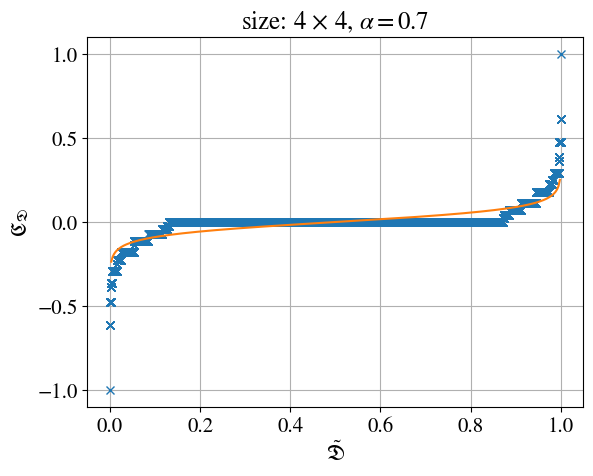

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os
from scipy.optimize import curve_fit

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a = 0.7
# DM.Jx = DM.Jy = a
# DM.Jz = 3 - 2*a

DM.Jx = DM.Jy = a/3
DM.Jz = 1 - 2*a/3

# if os.path.isfile(DM.datapath + '/CoeTable.json'):
#     with open(DM.datapath + '/CoeTable.json', 'r') as file:
#         coe_dict = json.load(file)
# else:
#     DM.calculate_CoefficientTable_approx(lazy=False)
#     with open(DM.datapath + '/CoeTable_approx.json', 'r') as file:
#         coe_dict = json.load(file)

coe_info = np.array(list(DM.calculate_CoefficientTable(update=True).values()))
coe_list = coe_info[:,1]
coe_list.sort()

print(f'Sum rule check: {DM.norm_cond_test(approximate=False, lazy=False)}')

# normalized_config = np.hstack((np.arange(DM.num_total_config)[:int(len(coe_list)/2)], 
#                                np.arange(DM.num_total_config)[-int(len(coe_list)/2):])) / DM.num_total_config
normalized_config = np.arange(len(coe_list)) / len(coe_list)
plt.plot(normalized_config, coe_list, 'x')

plt.title(fr'size: {DM.width} $\times$ {DM.height}, $\alpha={{{a}}}$')
plt.xlabel(r'$\tilde{\mathfrak{D}}$')
plt.ylabel(r'$\mathfrak{C}_{\mathfrak{D}}$')
plt.grid()
plt.tight_layout

step = 100
curvfit_x_range = normalized_config[step::step]
func_fit = lambda x, T: -T*np.log(1/x - 1)
T_fit, err = curve_fit(f=func_fit, xdata=curvfit_x_range, ydata=coe_list[step::step])
print(f'T_fit = {T_fit}')
plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, T=T_fit), '-')

os.makedirs(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}', exist_ok=True)
plt.savefig(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}/Jx_{DM.Jx:.3f}_Jy_{DM.Jy:.3f}_Jz_{DM.Jz:.3f}.pdf', dpi=300)


import csv
with open(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}/Jx_{DM.Jx:.3f}_Jy_{DM.Jy:.3f}_Jz_{DM.Jz:.3f}.csv', 'w') as file:
    writer = csv.writer(file)
    writer.writerow(coe_list)

### Comparism with different values of $\alpha$

Creating coefficient table for Jx=0.000, Jy=0.000, Jz=1.000, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.000, 0.000, 1.000
Sum rule chack: 1.0
Creating coefficient table for Jx=0.111, Jy=0.111, Jz=0.778, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.111, 0.111, 0.778
Sum rule chack: 0.999999999999984
Creating coefficient table for Jx=0.222, Jy=0.222, Jz=0.556, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.222, 0.222, 0.556
Sum rule chack: 1.000000000000017
Creating coefficient table for Jx=0.333, Jy=0.333, Jz=0.333, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progres

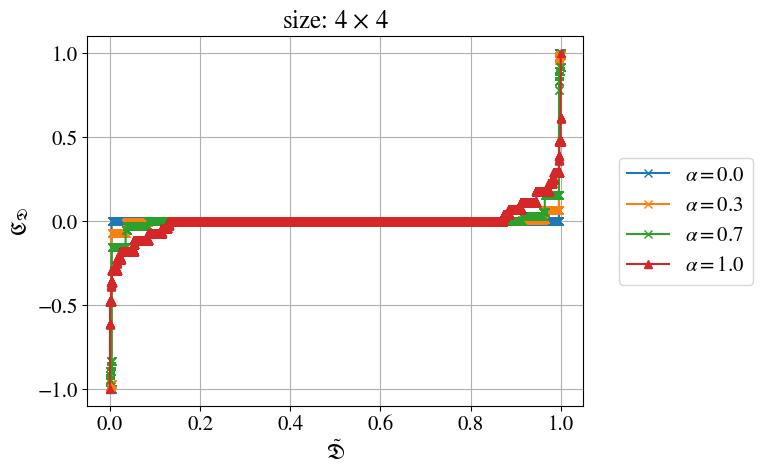

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 1, 4, endpoint=True)
for a in a_range:
    DM.Jx = DM.Jy = a/3
    DM.Jz = 1 - 2*a/3

    # if os.path.isfile(DM.datapath + '/CoeTable.json'):
    #     with open(DM.datapath + '/CoeTable.json', 'r') as file:
    #         coe_dict = json.load(file)
    # else:
    #     DM.calculate_CoefficientTable()
    #     with open(DM.datapath + '/CoeTable.json', 'r') as file:
    #         coe_dict = json.load(file)
    coe_info = np.array(list(DM.calculate_CoefficientTable(update=True).values()))
    coe_list = coe_info[:,1]
    coe_list.sort()
    print('Jx,Jy,Jz = %.3f, %.3f, %.3f' % (DM.Jx, DM.Jy, DM.Jz))

    print(f'Sum rule chack: {sum(np.array(coe_list)**2) / 2**(DM.N/2)}')

    if a < 3/4:
        normalized_config = np.arange(len(coe_list)) / len(coe_list)
        plt.plot(normalized_config, coe_list, '-x', label=rf'$\alpha = {{{a:.1f}}}$')
    else:
        normalized_config = np.arange(len(coe_list)) / len(coe_list)
        plt.plot(normalized_config, coe_list, '-^', label=rf'$\alpha = {{{a:.1f}}}$')

plt.title(fr'size: {DM.width} $\times$ {DM.height}')
plt.xlabel(r'$\tilde{\mathfrak{D}}$')
plt.ylabel(r'$\mathfrak{C}_{\mathfrak{D}}$')
plt.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
plt.grid()
plt.tight_layout

os.makedirs(f'figures/coefficients-distribution', exist_ok=True)
plt.savefig(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}_compare.pdf', dpi=300)

### Find the most important configurations

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os
from SpinModelDM import number_to_config

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a = 1
DM.Jx = DM.Jy = a
DM.Jz = 3 - 2*a

# DM.Jx = DM.Jy = a/3
# DM.Jz = 1 - 2*a/3

if os.path.isfile(DM.datapath + '/CoeTable.json'):
    with open(DM.datapath + '/CoeTable.json', 'r') as file:
        coe_dict = json.load(file)
else:
    DM.calculate_CoefficientTable()
    with open(DM.datapath + '/CoeTable.json', 'r') as file:
        coe_dict = json.load(file)

coe_list = np.array([coe_dict['%d'%n] for n in np.arange(DM.num_total_config)])
sorted_index = np.argsort(coe_list)
sorted_coe_array = coe_list[sorted_index]

# plt.plot(np.arange(DM.num_total_config), sorted_coe_array)

for label in np.arange(5000):
    # print(f'config: {number_to_config(N=DM.N, number=sorted_index[label])}; coe = {sorted_coe_array[label]}')
    print(f'config: {number_to_config(N=DM.N, number=sorted_index[-label-1])}; coe = {sorted_coe_array[-label-1]}')

config: ([], []); coe = 1.0
config: ([], []); coe = 1.0
config: ([1, 3, 7, 9, 11, 13, 15], [0, 4, 6, 8, 10, 12, 14]); coe = 0.6118033988749895
config: ([1], [14]); coe = 0.6118033988749895
config: ([3], [12]); coe = 0.6118033988749895
config: ([11], [4]); coe = 0.6118033988749895
config: ([15], [8]); coe = 0.6118033988749895
config: ([5], [2]); coe = 0.6118033988749895
config: ([13], [10]); coe = 0.6118033988749895
config: ([9], [6]); coe = 0.6118033988749895
config: ([7], [0]); coe = 0.6118033988749895
config: ([3, 5, 7, 9, 11, 13, 15], [0, 2, 4, 6, 8, 10, 12]); coe = 0.6118033988749894
config: ([1, 3, 5, 9, 11, 13, 15], [2, 4, 6, 8, 10, 12, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 9, 11, 15], [0, 2, 4, 6, 8, 12, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 9, 11, 13], [0, 2, 4, 6, 10, 12, 14]); coe = 0.6118033988749894
config: ([1, 5, 7, 9, 11, 13, 15], [0, 2, 4, 6, 8, 10, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 11, 13, 15], [0, 2, 4, 8, 10, 12, 14]);

In [12]:
DM.Coefficient_engine(setA=[1, 3, 7, 9, 11, 13, 15], setB=[0, 4, 6, 8, 10, 12, 14])

np.float64(0.6118033988749895)

![illustration](notes/Kitaev-GME/figures/minimal-system_brick-wall_diagonal.svg)

# Computing the ground state density matrix

Notice that the format of the output and the saved density matrix is ``scipy.sparse``. To load the density matrix, please use ``sp.load_npz`` instead of ``np.load``.

In [22]:
# rho = DM.density_matrix(update=True)

# Magic Transition

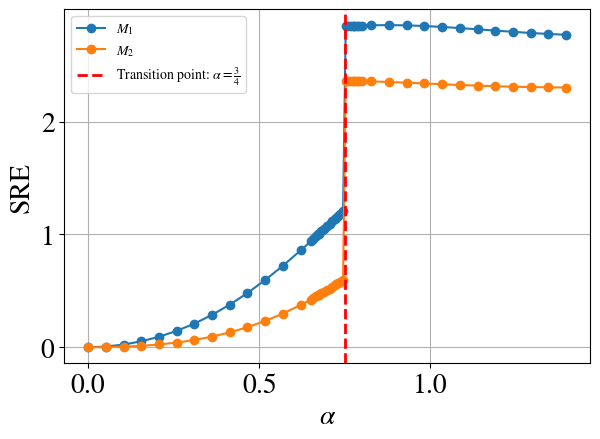

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 3/2, 30, endpoint=True)
a_range = np.concatenate((a_range, 
                          np.linspace(0.65, 0.8, 20, endpoint=True)))
a_range.sort()

### exact
for n in [1,2]:
    entropy_data = np.zeros_like(a_range)
    index = 0
    for a in a_range:
        DM.Jx = DM.Jy = a/3
        DM.Jz = 1 - 2*a/3

        entropy_data[index] = DM.stab_renyi_entropy(alpha=n, update=False) 
        index += 1

    plt.plot(a_range[:-2], entropy_data[:-2], '-o', label= r'$M_{{{}}}$'.format(n))


plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$\alpha$')
plt.ylabel('SRE')
plt.legend(fontsize='10')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()
plt.grid()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d.pdf' % (DM.width, DM.height), dpi=300)

## RDM magic transition

Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Creating coefficient table for Jx=0.000, Jy=0.000, Jz=1.000, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Creating coefficient table for Jx=0.013, Jy=0.013, Jz=0.974, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 1

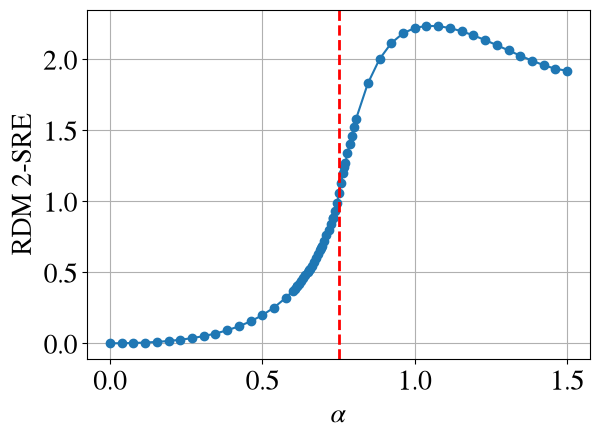

In [4]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height, 
                thermo_limit=True) # create a module

a_range = np.linspace(0, 3/2, 40, endpoint=True)
a_range = np.concatenate((a_range, 
                          np.linspace(0.6, 0.8, 30, endpoint=True)))
a_range.sort()

### exact
entropy_data = np.zeros_like(a_range)
index = 0
for a in a_range:
    DM.Jx = DM.Jy = a/3
    DM.Jz = 1 - 2*a/3
    # DM.calculate_CorrTable()

    entropy_data[index] = DM.RDM_2_stab_renyi_entropy(update=True, thermo_limit=True) 
    index += 1

# plt.plot(a_range[:-5], entropy_data[:-5], '-o')
plt.plot(a_range, entropy_data, '-o')


plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$\alpha$')
plt.ylabel('RDM 2-SRE')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()
plt.grid()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d_thermolimit.pdf' % (DM.width, DM.height), dpi=300)

## Finite-Size RDM SRE

Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10

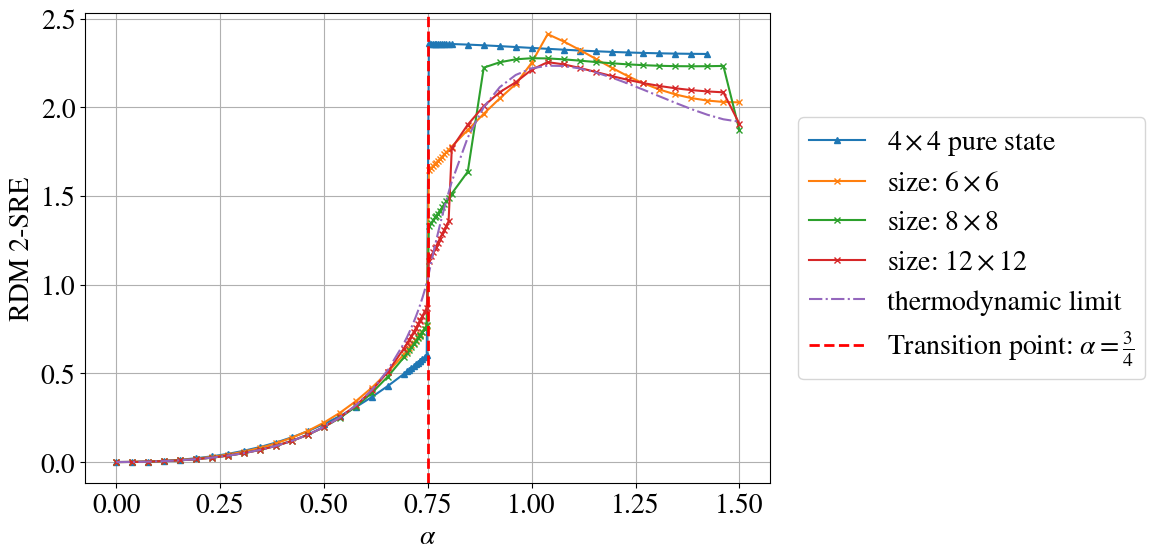

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 3/2, 40, endpoint=True)
a_range = np.concatenate((a_range, 
                          np.linspace(0.7, 0.8, 20, endpoint=True)))
a_range.sort()
# a_range = np.linspace(0, 3/2, 3, endpoint=True)

fig, ax = plt.subplots(figsize=(12, 6))
markersize = 5

### pure state
entropy_data = np.zeros_like(a_range)
index = 0
for a in a_range:
    DM.Jx = DM.Jy = a/3
    DM.Jz = 1 - 2*a/3
    # DM.calculate_CorrTable()
    entropy_data[index] = DM.stab_renyi_entropy(n=2) 
    index += 1

ax.plot(a_range[:-2], entropy_data[:-2], '-^', markersize=markersize,
        label=rf'${{{4}}}\times{{{4}}}$ pure state')

### RDM SRE
for tot_size in [6, 8, 12]:
    entropy_data = np.zeros_like(a_range)
    index = 0
    for a in a_range:
        DM.Jx = DM.Jy = a/3
        DM.Jz = 1 - 2*a/3
        # DM.calculate_CorrTable(tot_size=[tot_size,tot_size])
        entropy_data[index] = DM.RDM_2_stab_renyi_entropy(tot_size=[tot_size,tot_size]) 
        index += 1

    # plt.plot(a_range[:-5], entropy_data[:-5], '-o')
    ax.plot(a_range, entropy_data, '-x', markersize=markersize,
            label=rf'size: ${{{tot_size}}}\times{{{tot_size}}}$')

### thermodynamic limit
DM.thermo_limit = True
entropy_data = np.zeros_like(a_range)
index = 0
for a in a_range:
    DM.Jx = DM.Jy = a/3
    DM.Jz = 1 - 2*a/3
    # DM.calculate_CorrTable()
    entropy_data[index] = DM.RDM_2_stab_renyi_entropy(update=False, thermo_limit=True) 
    index += 1
ax.plot(a_range, entropy_data, '-.', markersize=markersize,
        label='thermodynamic limit')

ax.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('RDM 2-SRE')
ax.grid()
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
# ax.set_aspect('auto')
fig.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
fig.savefig('figures/stab-renyi-entropy/w_%d_h_%d_finite_RDM.pdf' % (DM.width, DM.height), dpi=300)

## SRE density of different subsystem sizes in the infinitily large background system

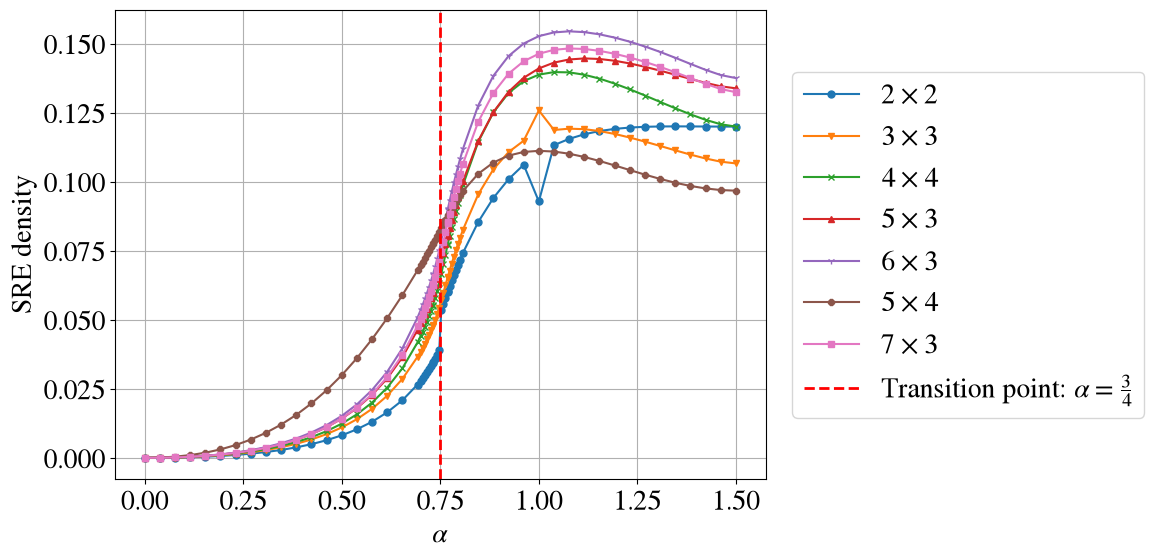

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

a_range = np.linspace(0, 3/2, 40, endpoint=True)
a_range = np.concatenate((a_range, 
                          np.linspace(0.7, 0.8, 20, endpoint=True)))
a_range.sort()
# a_range = np.linspace(0, 3/2, 3, endpoint=True)

fig, ax = plt.subplots(figsize=(12, 6))
markersize = 5

### RDM SRE density
# for square_edge in [2,3,4]:
#     DM = SpinSystem(width=square_edge, height=square_edge, thermo_limit=True) # create a module
#     entropy_data = np.zeros_like(a_range, dtype=float)
#     index = 0
#     for a in a_range:
#         DM.Jx = DM.Jy = a/3
#         DM.Jz = 1 - 2*a/3
#         # DM.calculate_CorrTable(tot_size=[tot_size,tot_size])
#         entropy_data[index] = DM.RDM_2_stab_renyi_entropy(thermo_limit=True, corr_table_sys_size=[10,10]) 
#         index += 1

#     # plt.plot(a_range[:-5], entropy_data[:-5], '-o')
#     ax.plot(a_range, entropy_data/(square_edge**2), '-o', markersize=markersize,
#             label=rf'${{{square_edge}}}\times{{{square_edge}}}$')

dottype = ['o', 'v', 'x', '^', '1', '8', 's', 'p', 'P', '*', 'h', 'H', '+', 'D', 'd']
data_count = 0
for sub_size in [[2,2], [3,3], [4,4], [5,3], [6,3], [5,4], [7,3]]:
    DM = SpinSystem(width=sub_size[0], height=sub_size[1], thermo_limit=True) # create a module
    entropy_data = np.zeros_like(a_range, dtype=float)
    index = 0
    for a in a_range:
        DM.Jx = DM.Jy = a/3
        DM.Jz = 1 - 2*a/3
        # DM.calculate_CorrTable(tot_size=[tot_size,tot_size])
        entropy_data[index] = DM.RDM_2_stab_renyi_entropy(thermo_limit=True, corr_table_sys_size=[10,10]) 
        index += 1

    # plt.plot(a_range[:-5], entropy_data[:-5], '-o')
    ax.plot(a_range, entropy_data/(sub_size[0] * sub_size[1]), '-' + dottype[data_count], 
            markersize=markersize,
            label=rf'${{{sub_size[0]}}}\times{{{sub_size[1]}}}$')
    data_count += 1


ax.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('SRE density')
ax.grid()
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
# ax.set_aspect('auto')
fig.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
fig.savefig('figures/stab-renyi-entropy/subsys_SRE_size_compare.pdf', dpi=300)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
from scipy import linalg as la

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module
DM.Jx, DM.Jy, DM.Jz = 0, 0, 1
DM.full_corr_mat_update(tot_size=[12,12])
la.det(np.eye(DM.N) + DM.full_corr_mat)

Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10


np.float64(551368.0)

## Magic Transition with Magnetic Field

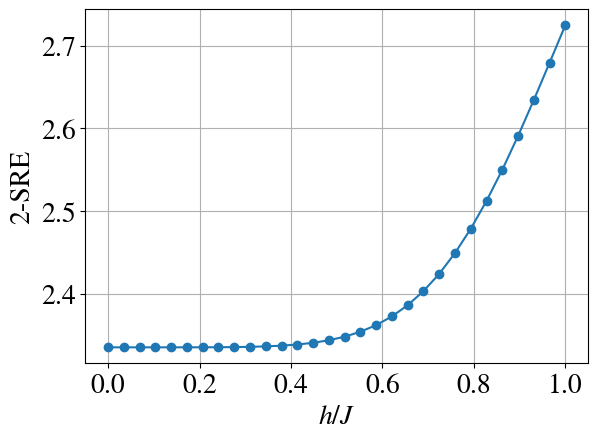

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

h_range = np.linspace(0, 1, 30, endpoint=True)
# a_range = np.concatenate((a_range, np.linspace(0.65, 0.8, 10, endpoint=True)))
# a_range.sort()

### exact
a = 1
DM.Jx = DM.Jy = a/3
DM.Jz = 1 - 2*a/3

index = 0
entropy_data = np.zeros_like(h_range)
for h in h_range:
    DM.h = h * DM.Jz

    entropy_data[index] = DM.stab_renyi_entropy(n=2, update=False) 
    index += 1

plt.plot(h_range, entropy_data, '-o')


# plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
#             color='red', 
#             linestyle='--', 
#             linewidth=2, 
#             label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$h/J$')
plt.ylabel('2-SRE')
plt.grid()
# plt.legend(fontsize='10')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d_vs-mag.pdf' % (DM.width, DM.height), dpi=300)

# Magic Phase Diagram

Matplotlib is building the font cache; this may take a moment.


Figure saved to: D:\github-work-station\Kitaev-magic\figures\SRE_figures\figures\stab-renyi-entropy\w_4_h_4_magic-phase-diagram.pdf


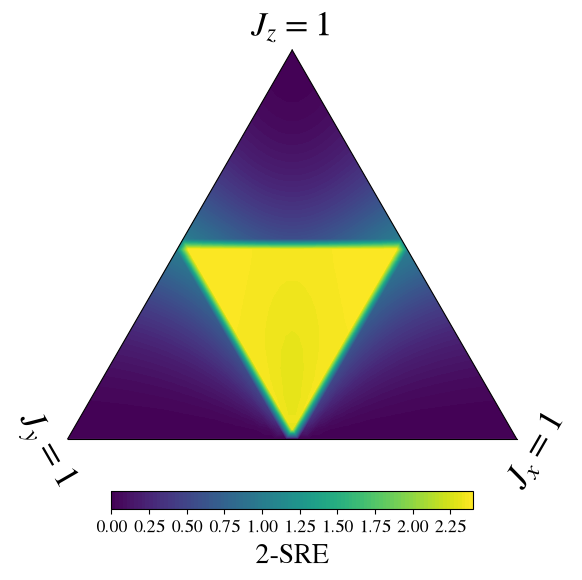

In [1]:
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import mpltern  # generate the ternaty projection 

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 13})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

# 1. Generate ternary grid coordinates: J_x + J_y + J_z = 1
n_points = 40
jx = np.linspace(0, 1, n_points)
jy = np.linspace(0, 1, n_points)
jz = np.linspace(0, 1, n_points)

# Create meshgrid over ternary simplex
t, l, r = np.meshgrid(jx, jy, jz, indexing='ij')
mask = np.abs(t + l + r - 1.0) < 1e-3  # Keep only points where sum = 1

T = t[mask]  # Top apex: J_z
L = l[mask]  # Left apex: J_x
R = r[mask]  # Right apex: J_y

# 2. Define or generate your scalar data (e.g. SRE density m1)
# m1_data = np.zeros_like(T)
# for n in range(len(T)):
#     DM.Jz, DM.Jx, DM.Jy = T[n], L[n], R[n]
#     m1_data[n] = DM.stab_renyi_entropy(alpha=2, update=False) 
m1_data = np.load('magic_data.npy')

# 3. Create Ternary Figure
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='ternary')

# 4. Plot heatmap using tricontourf
cs = ax.tricontourf(T, L, R, m1_data, 
                    levels=100, 
                    cmap='viridis')

# 5. Draw Phase Boundaries (Dashed inner triangle for gapless/gapped transition)
# Boundary equations: J_alpha = J_beta + J_gamma => J_alpha = 0.5 when J_x + J_y + J_z = 1
# ax.plot([0.5, 0.5, 0],   [0.5, 0, 0.5],   [0, 0.5, 0.5], 
#         color='black', linestyle='--', linewidth=1.5)

# 6. Set Axis Labels & Formatting
text_font_size = 25
ax.set_tlabel(r'$J_z = 1$', fontsize=text_font_size)
ax.set_llabel(r'$J_y = 1$', fontsize=text_font_size)
ax.set_rlabel(r'$J_x = 1$', fontsize=text_font_size)

# Custom tick formatting and appearance
ax.taxis.set_ticks([])
ax.laxis.set_ticks([])
ax.raxis.set_ticks([])

# 7. Add Horizontal Colorbar at the bottom
cbar = fig.colorbar(cs, ax=ax, orientation='horizontal', pad=0.1, shrink=0.7)
cbar.set_label('2-SRE', fontsize=20)

plt.tight_layout()

output_dir = Path.cwd() / "figures" / "stab-renyi-entropy"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / (
    f"w_{DM.width}_h_{DM.height}_magic-phase-diagram.pdf"
)

fig.tight_layout()
fig.savefig(output_file, dpi=300, bbox_inches="tight")
print(f"Figure saved to: {output_file.resolve()}")

plt.show()
plt.close(fig)

## Magic Phase Diagram: Thermodynamic Limit

Figure saved to: D:\github-work-station\Kitaev-magic\figures\SRE_figures\figures\stab-renyi-entropy\w_4_h_4_magic-phase-diagram_thermolimit.pdf


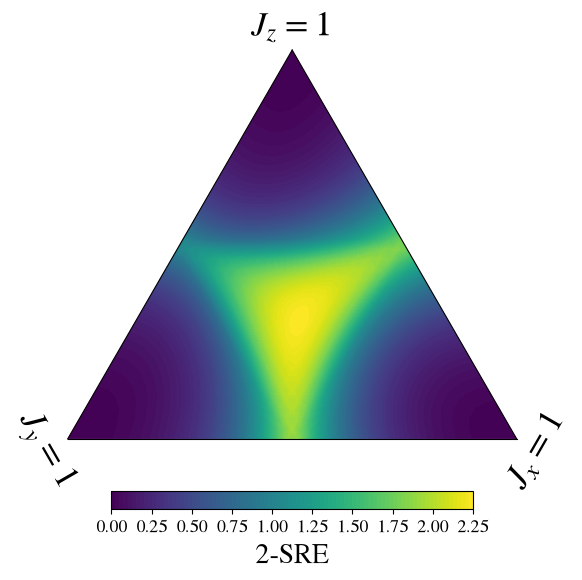

In [2]:
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import mpltern  # generate the ternaty projection 

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 13})

width = 4
height = 4
DM = SpinSystem(width=width, height=height, thermo_limit=True) # create a module

# 1. Generate ternary grid coordinates: J_x + J_y + J_z = 1
n_points = 40
jx = np.linspace(0, 1, n_points)
jy = np.linspace(0, 1, n_points)
jz = np.linspace(0, 1, n_points)

# Create meshgrid over ternary simplex
t, l, r = np.meshgrid(jx, jy, jz, indexing='ij')
mask = np.abs(t + l + r - 1.0) < 1e-3  # Keep only points where sum = 1

T = t[mask]  # Top apex: J_z
L = l[mask]  # Left apex: J_x
R = r[mask]  # Right apex: J_y

# 2. Define or generate your scalar data (e.g. SRE density m1)
# m1_data = np.zeros_like(T)
# for n in range(len(T)):
#     DM.Jz, DM.Jx, DM.Jy = T[n], L[n], R[n]
#     m1_data[n] = DM.RDM_2_stab_renyi_entropy(update=False, thermo_limit=True) 
m1_data = np.load('RDM_2_stab_renyi_entropy_termolimit.npy')

# 3. Create Ternary Figure
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='ternary')

# 4. Plot heatmap using tricontourf
cs = ax.tricontourf(T, L, R, m1_data, 
                    levels=100, 
                    cmap='viridis')

# 5. Draw Phase Boundaries (Dashed inner triangle for gapless/gapped transition)
# Boundary equations: J_alpha = J_beta + J_gamma => J_alpha = 0.5 when J_x + J_y + J_z = 1
# ax.plot([0.5, 0.5, 0],   [0.5, 0, 0.5],   [0, 0.5, 0.5], 
#         color='black', linestyle='--', linewidth=1.5)

# 6. Set Axis Labels & Formatting
text_font_size = 25
ax.set_tlabel(r'$J_z = 1$', fontsize=text_font_size)
ax.set_llabel(r'$J_y = 1$', fontsize=text_font_size)
ax.set_rlabel(r'$J_x = 1$', fontsize=text_font_size)

# Custom tick formatting and appearance
ax.taxis.set_ticks([])
ax.laxis.set_ticks([])
ax.raxis.set_ticks([])

# 7. Add Horizontal Colorbar at the bottom
cbar = fig.colorbar(cs, ax=ax, orientation='horizontal', pad=0.1, shrink=0.7)
cbar.set_label('2-SRE', fontsize=20)

plt.tight_layout()

output_dir = Path.cwd() / "figures" / "stab-renyi-entropy"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / (
    f"w_{DM.width}_h_{DM.height}_magic-phase-diagram_thermolimit.pdf"
)

fig.tight_layout()
fig.savefig(output_file, dpi=300, bbox_inches="tight")
print(f"Figure saved to: {output_file.resolve()}")

plt.show()
plt.close(fig)

### Magic Scaling

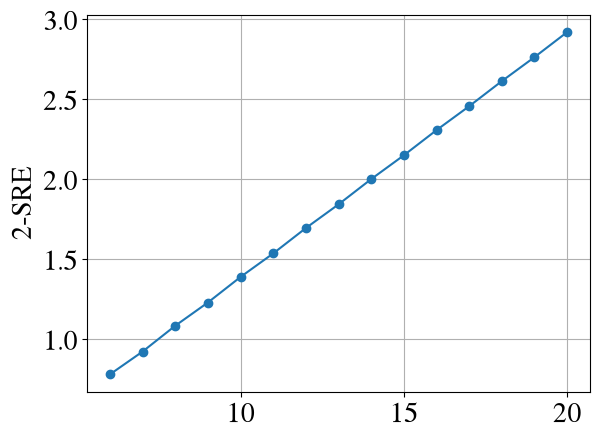

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

w_range = np.arange(6,21)
a = 3/2
### exact
index = 0
entropy_data = np.zeros_like(w_range, dtype=float)
for width in w_range:
    DM = SpinSystem(width=width, height=1, 
                    Jx=a/3, Jy=a/3, Jz=1 - a*2/3,
                    thermo_limit=True) # create a module
    # DM.calculate_CorrTable()
    entropy_data[index] = DM.RDM_2_stab_renyi_entropy(thermo_limit=True, 
                                                      corr_table_sys_size=[30,1]) 
    index += 1
    
plt.plot(w_range, entropy_data, '-o')

# plt.xlabel(r'$$')
plt.ylabel('2-SRE')
plt.grid()
# plt.legend(fontsize='10')
plt.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_a_{a}.pdf', dpi=300)

C:\Users\goodw\AppData\Local\Temp\ipykernel_9072\3323420280.py:33: RuntimeWarning: invalid value encountered in scalar divide
  print(f'alpha={a:.1f}: a={a_fit}, b={b_fit}, -b/a={-a_fit/b_fit}')


alpha=0.0: a=0.0, b=0.0, -b/a=nan
alpha=0.5: a=0.015768433819711002, b=-0.015508909077176761, -b/a=1.0167339134714617
alpha=1.0: a=0.13846198653083105, b=-0.11393528868032128, -b/a=1.2152686681588756
alpha=1.5: a=0.15310716195863872, b=-0.14325540953752802, -b/a=1.0687705438343664


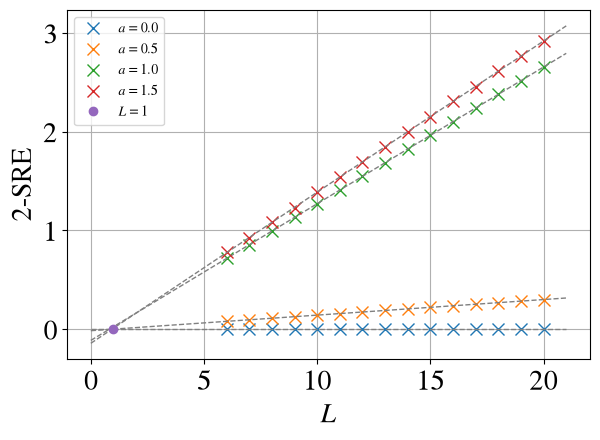

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os
from scipy.optimize import curve_fit

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

w_range = np.arange(6,21)
a_range = np.linspace(0,3/2,4, endpoint=True)
curvfit_x_range = np.linspace(0, 21)
### exact
for a in a_range:
    index = 0
    entropy_data = np.zeros_like(w_range, dtype=float)
    for width in w_range:
        DM = SpinSystem(width=width, height=1, 
                        Jx=a/3, Jy=a/3, Jz=1 - a*2/3,
                        thermo_limit=True) # create a module
        entropy_data[index] = DM.RDM_2_stab_renyi_entropy(thermo_limit=True, 
                                                        corr_table_sys_size=[30,1]) 
        index += 1
    
    plt.plot(w_range, entropy_data, 'x', label=rf'$a = {{{a:.1f}}}$', markersize=8)

    func_fit = lambda x, a, b: a*x + b
    coe_fit, err = curve_fit(f=func_fit, xdata=w_range, ydata=entropy_data)
    [a_fit, b_fit] = coe_fit
    plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, a=a_fit, b=b_fit), '--', color='gray', linewidth=1)
    print(f'alpha={a:.1f}: a={a_fit}, b={b_fit}, -b/a={-a_fit/b_fit}')

plt.plot([1], [0], 'o', label=r'$L=1$')
plt.xlabel(r'$L$')
plt.ylabel('2-SRE')
plt.grid()
plt.legend(fontsize='10')
plt.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
# plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_a_{a}.pdf', dpi=300)
plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_compare.pdf', dpi=300)

# Mutual SRE of a Vertial Loop

$$
W_{2}(l) = \frac{1}{4}\ln\left[\left(\frac{L}{\pi}\right)\sin\left(\frac{\pi l}{L}\right)\right]
$$

a = 0.23458 +/- 0.00075,  b = 0.66046 +/- 0.00123


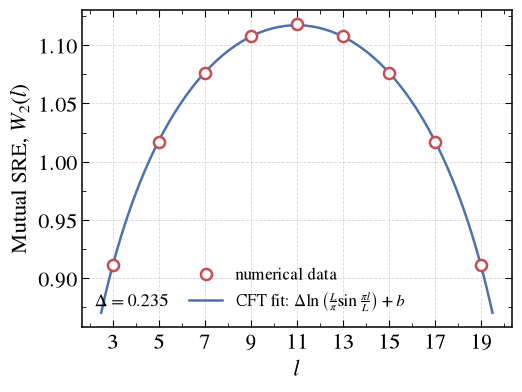

In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os
from scipy.optimize import curve_fit
from SpinModelDM import SpinSystem

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({
    'font.size': 16,
    'axes.linewidth': 1.1,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'xtick.top': True,
    'ytick.right': True,
})

L_tot = 22  # total length
l_range_ini = np.arange(2, L_tot + 1 - 2)
l_range = np.array([n for n in l_range_ini if n % 2 == 1])  # odd separations only

p = 0.5
Jx, Jy = [1-p, p]

DM = SpinSystem()

update_entropy = False
if update_entropy:
    index = 0
    entropy_data = np.zeros_like(l_range, dtype=float)
    for l in l_range:
        entropy_data[index] = DM.mutual_SRE_1D(Jx=Jx, Jy=Jy, L=L_tot, l=l) 
        index += 1
    np.save(f'1Dmutual-SRE_Jx_{Jx}_Jy_{Jy}', entropy_data)
else:
    entropy_data = np.load(f'1Dmutual-SRE_Jx_{Jx}_Jy_{Jy}.npy')

################ CFT fit ################
if Jx == Jy:
    l_conf = lambda x: (L_tot / np.pi) * np.sin(np.pi * x / L_tot)
    func_fit = lambda x, a, b: a * np.log(l_conf(x=x)) + b
    coe_fit, cov_fit = curve_fit(f=func_fit, xdata=l_range, ydata=entropy_data)
    a_fit, b_fit = coe_fit
    a_err, b_err = np.sqrt(np.diag(cov_fit))
    print(f'a = {a_fit:.5f} +/- {a_err:.5f},  b = {b_fit:.5f} +/- {b_err:.5f}')

    curvfit_x_range = np.linspace(l_range.min() - 0.5, l_range.max() + 0.5, 300)

################ Figure ################
fig, ax = plt.subplots(figsize=(5.5, 4.2))

# data points
ax.plot(l_range, entropy_data, 'o', markersize=8, markerfacecolor='white',
        markeredgecolor='#C44E52', markeredgewidth=1.8, zorder=3, label='numerical data')

if Jx == Jy:
    # fit curve
    ax.plot(curvfit_x_range, func_fit(x=curvfit_x_range, a=a_fit, b=b_fit),
            '-', color='#4C72B0', linewidth=1.8, zorder=2,
            label=r'CFT fit: $\Delta\ln\left(\frac{L}{\pi}\sin\frac{\pi l}{L}\right)+b$')
    # annotate fit coefficient
    ax.text(0.03, 0.05, rf'$\Delta = {a_fit:.3f}$', transform=ax.transAxes,
            fontsize=13, va='bottom', ha='left')
    ax.legend(frameon=False, fontsize=12, loc='lower center')

ax.set_xlabel(r'$l$')
ax.set_ylabel(r'Mutual SRE, $W_2(l)$')

ax.set_xticks(np.arange(3, 20, step=2))
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))

ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.5)


fig.tight_layout()

file_path = 'figures/stab-renyi-entropy'
os.makedirs(file_path, exist_ok=True)
fig.savefig(file_path + f'/mutual_SRE_Jx_{Jx}_Jy_{Jy}.pdf', dpi=300, bbox_inches="tight")

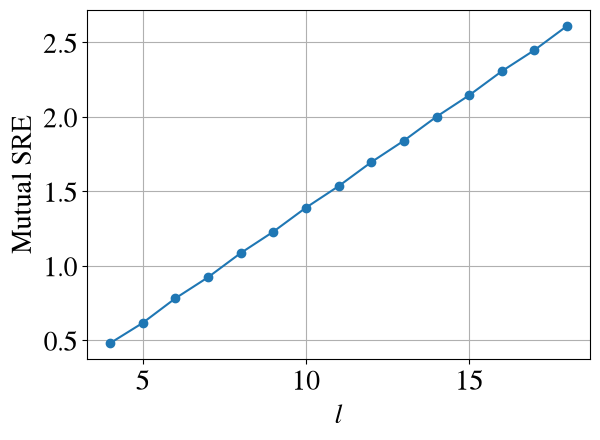

In [28]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os
# from scipy.optimize import curve_fit

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

DM = SpinSystem(Jx=1/2, Jy=1/2, Jz=0) # create a module

l_range = np.arange(4,19)
# curvfit_x_range = np.linspace(0, 21)
### exact
index = 0
entropy_data_1 = np.zeros_like(l_range, dtype=float)
for l in l_range:
    DM.width = l
    DM.height = 1
    entropy_data_1[index] = DM.RDM_2_stab_renyi_entropy(tot_size=[22, 'infty'], 
                                                      corr_table_sys_size=[22, 1])
    index += 1

plt.plot(l_range, entropy_data_1, '-o')

# func_fit = lambda x, a, b: a*x + b
# coe_fit, err = curve_fit(f=func_fit, xdata=w_range, ydata=entropy_data)
# [a_fit, b_fit] = coe_fit
# plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, a=a_fit, b=b_fit), '--', color='gray', linewidth=1)
# print(f'alpha={a:.1f}: a={a_fit}, b={b_fit}, -b/a={-a_fit/b_fit}')

plt.xlabel(r'$l$')
plt.ylabel('Mutual SRE')
plt.grid()
# plt.legend(fontsize='10')
plt.tight_layout()

# os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
# plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_a_{a}.pdf', dpi=300)
# plt.savefig(f'figures/stab-renyi-entropy/mutual_SRE.pdf', dpi=300)

## Different vertical cylinfrical circumference

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os
from scipy.optimize import curve_fit

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

DM = SpinSystem() # create a module


w_range_init = np.arange(4,21)   # the circumference of the cylinder
w_range = np.array([n for n in w_range_init if n%2==0])
curvfit_x_range = np.linspace(0, 21)
### exact
index = 0
entropy_data = np.zeros_like(w_range, dtype=float)
for l in w_range:
    DM.width= l
    entropy_data[index] = DM.SRE_1D(Jx=1/2, Jy=1/2, tot_length=l)
    index += 1

plt.plot(w_range, entropy_data, 'x', markersize=8)

func_fit = lambda x, a, b: a*x + b
coe_fit, err = curve_fit(f=func_fit, xdata=w_range, ydata=entropy_data)
[a_fit, b_fit] = coe_fit
plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, a=a_fit, b=b_fit), '--', color='gray', linewidth=1)
print(f'a={a_fit}, b={b_fit}, -b/a={-a_fit/b_fit}')

plt.xlabel(r'$l$')
plt.ylabel('2-SRE')
plt.grid()
# plt.legend(fontsize='10')
plt.tight_layout()

# os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
# plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_a_{a}.pdf', dpi=300)
# plt.savefig(f'figures/stab-renyi-entropy/mutual_SRE.pdf', dpi=300)

Creating coefficient table for Jx=0.500, Jy=0.500, Jz=0.000, mag=0.000
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Creating coefficient table for Jx=0.500, Jy=0.500, Jz=0.000, mag=0.000
Progress: Making Correlation Matrix
Creating CorrTable
CorrTable creation complete
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10


This function has a zero exactly when

$$
\cos(2\pi k_1) = -\frac{J_x^2+J_y^2}{2J_xJ_y}\ \xrightarrow{J_x=J_y}\ \cos(2\pi k_1)=-1 \iff k_1=\tfrac12 .
$$

So **only at $J_x=J_y$** does the chain become gapless, with the closing point sitting exactly at $k_1=1/2$. This is precisely the self-dual/critical point of the finite Kitaev chain discussed in your Appendix B — away from it ($J_x\neq J_y$), $s_{k_1}$ never vanishes and the chain is gapped everywhere.

For a ring of $n$ unit cells with PBC, the allowed momenta are $k_1 = j/n,\ j=0,\dots,n-1$. The special point $k_1=1/2$ is in this discrete set **iff $n$ is even** ($j=n/2$).

- When $n$ is even, one momentum mode sits exactly at the gap closing. There, `corr_integrand` hits `epsilon == 0` and (correctly) returns 0 to avoid the $0/0$ — this is the code's way of saying that mode's occupation is *undetermined* (both branches are degenerate in energy), i.e. a genuine **unpaired Majorana zero mode / two-fold degenerate ground state** for that wire. In the correlation-matrix language this shows up as one exact eigenvalue $\nu_k=0$ (maximally mixed), while every other mode is fully pure ($\nu_k=1$).
- When $n$ is odd, $k_1=1/2$ is never sampled, so **every** mode stays gapped and pure ($\nu_k=1$ for all $k$, as I verified numerically above).

As we found before, at $J_x=J_y$ (the critical/self-dual point of the decoupled wire) the dispersion $s_{k_1}=2\sqrt{J_x^2+J_y^2+2J_xJ_y\cos(2\pi k_1)}$ touches zero exactly at $k_1=1/2$. This momentum is included in the ring's discrete spectrum $\{j/n\}$ iff $n=L/2$ is even, producing exactly one unpaired zero mode ($\nu_k=0$), i.e. a two-fold-degenerate ground state for that decoupled wire. That single zero mode contributes exactly one bit ($\ln 2$) regardless of how long the chain is — it's a boundary/resonance effect, not a bulk one, so it correctly stays bounded rather than scaling with $L$

Progress: Making Correlation Matrix
Creating CorrTable
CorrTable creation complete
Progress: 1/10
Progress: 2/10
Progress: 3/10
L=2, Renyi entropy=1.249999765216797e-07
Progress: Making Correlation Matrix
Creating CorrTable
CorrTable creation complete
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=4, Renyi entropy=1.2499997648074412e-07
Progress: Making Correlation Matrix
Creating CorrTable
CorrTable creation complete
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=6, Renyi entropy=1.1249992270932273e-06
Progress: Making Correlation Matrix
Creating CorrTable
CorrTable creation complete
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=8, Renyi entropy=6.249997895890758e-07
Prog

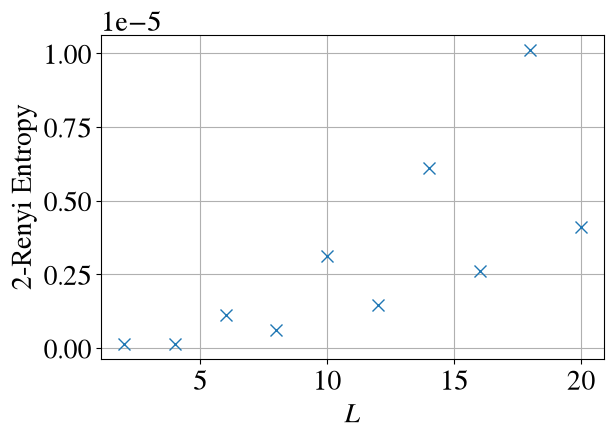

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os
from scipy.optimize import curve_fit

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

DM = SpinSystem() # create a module

w_range_init = np.arange(1, 21)   # the circumference of the cylinder
w_range = np.array([n for n in w_range_init if n%2==0])
curvfit_x_range = np.linspace(0, 21)
### exact
index = 0
entropy_data = np.zeros_like(w_range, dtype=float)
for l in w_range:
    DM.width, DM.height = l, 1
    entropy_data[index] = DM.renyi_entropy_1D(Jx=1/2, Jy=1/2, tot_length=l, update=True)
    index += 1

plt.plot(w_range, entropy_data, 'x', markersize=8)

# func_fit = lambda x, a, b: a*x + b
# coe_fit, err = curve_fit(f=func_fit, xdata=w_range, ydata=entropy_data)
# [a_fit, b_fit] = coe_fit
# plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, a=a_fit, b=b_fit), '--', color='gray', linewidth=1)
# print(f'a={a_fit}, b={b_fit}, -b/a={-a_fit/b_fit}')

plt.xlabel(r'$L$')
plt.ylabel('2-Renyi Entropy')
plt.grid()
# plt.legend(fontsize='10')
plt.tight_layout()

# os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
# plt.savefig(f'figures/stab-renyi-entropy/linear_scaling_a_{a}.pdf', dpi=300)
# plt.savefig(f'figures/stab-renyi-entropy/mutual_SRE.pdf', dpi=300)